# 05 -- Noise correlation: measuring it, and what it costs to ignore

**Goal:** measure whether real MUSE per-pixel noise is actually
independent, as every chi2 and error bar computed anywhere in this
package assumes by default -- and show the
practical consequence of getting this wrong, both on real data and on a
synthetic mock with known ground truth.

**Why this matters more than it sounds like it should.** `fit_losvd` and
the Laplace uncertainty both consume "whitened" inputs (`A_stack_w =
A_stack/errors`, `y_w = flux/errors`) and just compute
`sum(residual**2)` -- correct only if per-pixel noise really is
independent. MUSE spectra are resampled/drizzled onto a regular spatial
grid during pipeline reduction, a well-documented source of pixel-to-
pixel correlation (Bacon et al. 2017); if real pixels are correlated and
treated as independent, every chi2 and error bar in this package is
silently miscalibrated by the same systematic amount.

**Why correlation would look like an AR(1) process, physically.**
Resampling smooths a photon's contribution across its neighboring
*output* pixels (the literal mechanism behind "drizzling" onto a regular
grid from an irregular input sampling) -- so a noise fluctuation at pixel
`i` leaks a little into pixel `i+1`, less into `i+2`, and so on, decaying
with pixel separation. That decaying-with-distance signature is exactly
what an AR(1) model (`Sigma_ij = sigma_i * sigma_j * rho^|i-j|`)
describes. This notebook measures that decay directly rather than
assuming it, on real data (Sections 1-6) and on a synthetic mock built
with a known, injected `rho` (Section 7), where the effect on recovery
can be checked against ground truth directly.

**Roadmap**: load a real spectrum and fit it the way every other
notebook in this sequence does (Sections 1-2) -> measure the actual
pixel correlation in its residual, including a direct look at the
correlation structure itself (Section 3) -> connect that to the
literature (Section 4) -> refit properly accounting for it (Section 5)
-> see what changes, including for the reported uncertainty (Section 6)
-> confirm the whole mechanism against a synthetic mock with known truth
(Section 7) -> add the systematic residuals that dominate at high S/N,
sky lines and template mismatch, and the error bands that account for
them (Section 8).

## Primer: what "AR(1)" means, and how to read a `rho` value

This notebook leans on two ideas that are easy to skim past without
actually knowing what they mean. Both are worth pinning down before
Section 1, since everything below is really just measuring one number
(`rho`) and tracing its consequences.

**A correlation coefficient, in plain terms.** `rho` (or `r`) is a single
number between -1 and +1 that measures how strongly two quantities move
together. `rho = 0` means knowing one tells you nothing about the other
(independent). `rho = +1` means they move in perfect lockstep. `rho = -1`
means they move in perfect lockstep but in opposite directions. In noise
terms: if pixel `i`'s random fluctuation is unusually high, does pixel
`i+1`'s tend to also be high (positive `rho`), or is it unrelated (`rho`
near 0)? As a rough, commonly-used scale for "how big is this
correlation": |rho| below ~0.3 is usually called weak, 0.3-0.7 moderate,
above 0.7 strong. The `rho ~ 0.5` this notebook measures on a real,
high-S/N MUSE aperture is, by that scale, a *moderate* correlation -- enough
to widen the error bars by more than half (Section 6).

**What "AR(1)" means.** AR(1) ("autoregressive, order 1") is one of the
simplest standard models for correlated noise along a sequence (here, a
sequence of wavelength pixels). It says each pixel's noise is built from
a fraction `rho` of its *immediate* neighbor's noise, plus a fresh random
kick of its own:

```
noise[i] = rho * noise[i-1] + (fresh random kick)
```

Nothing here reaches past the immediate neighbor directly -- but that
one-step link still couples pixel `i` to pixel `i+2` *indirectly* (through
`i+1`), to `i+3` through both intermediate pixels, and so on. Working out
the math, this simple rule implies the correlation between two pixels
`k` apart is exactly `rho` raised to the `k`-th power: `rho^1` for
neighbors, `rho^2` two pixels apart, `rho^3` three pixels apart -- decaying
geometrically, fastest at first, and getting weaker (but technically
never quite zero) the further apart two pixels are. That's the whole
model: **one number, `rho`, sets both how strongly adjacent pixels are
linked and how fast that link fades with distance.** Section 3 measures
this decay directly and checks it actually looks geometric, not just
assumed.

**Why a correlated-noise model like this, physically, rather than
independent per-pixel noise.** See the paragraph below on MUSE's
resampling step -- it's the physical reason to expect *some* pixel-to-
pixel leakage in the first place, before any number has been measured.

## 1. Setup, and load a real, high-S/N NGC 4751 spectrum

Reuses the compact representative-aperture products shipped with this
package (produced by `04_template_calibration.ipynb`'s real-data
pipeline) -- the "high" S/N aperture, since a well-measured spectrum
gives the cleanest correlation estimate.

**Only the dust-free half of the galaxy is used.** NGC 4751's nearly edge-on dust disk obscures the galaxy on
one side of its kinematic major axis, so those spaxels are excluded (`../data/muse/ngc4751_nfm_kma_mask.txt`; see
`04_template_calibration.ipynb`, Section 2, for why), and the representative apertures come from the dust-free
half of the field only.

In [1]:
from __future__ import annotations
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, laplace_losvd_uncertainty, detect_emission_lines, build_spline_truth, full_pixel_model,
    build_ar1_covariance, whiten, measure_and_whiten, BACON2017_VARIANCE_CORRECTION_FACTOR,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import estimate_correlation_length

REP_BINS_PATH = "../data/muse/ngc4751_representative_bins.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc4751_template_subset.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
# Sky-line residual windows are fixed in the OBSERVED frame (the same OH lines as before); converted to this
# target's rest frame once Z is known, below.
SKY_RESIDUAL_WINDOWS_OBS = [
    (8427.6, 8432.6), (8462.7, 8467.7), (8725.1, 8728.1), (8762.7, 8767.2),
]

d = np.load(REP_BINS_PATH)
Z = float(d["z"])
SKY_RESIDUAL_WINDOWS = [(lo / (1 + Z), hi / (1 + Z)) for lo, hi in SKY_RESIDUAL_WINDOWS_OBS]
wave_obs, flux_obs, error_obs = d["wave_obs_high"], d["flux_obs_high"], d["error_obs_high"]
print(f"NGC 4751 (MUSE NFM, dust-free side of the KMA), z={Z:.6f}, high-S/N aperture: S/N~{float(d['snr_high']):.0f}")

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=all_windows)
_, errors = mask_wavelength_windows(wave_w, error_w, windows=all_windows)
print(f"{len(wave_fit)} pixels after sky/emission masking "
      f"({len(emission_windows)} emission window(s) detected)")

subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} templates")


NGC 4751 (MUSE NFM, dust-free side of the KMA), z=0.006985, high-S/N aperture: S/N~553
299 pixels after sky/emission masking (2 emission window(s) detected)
loaded 35 templates


## 2. Fit assuming independent pixels (`rho=0`, the package default)

A two-stage velocity grid: a wide first fit for a rough `(V, sigma)`, then a `V -+ 7 sigma` grid around it.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    cfg_wide = FitConfig(vmin=-3000.0, vmax=3000.0)  # NGC 4751's sigma is ~450-600 km/s at the center (was +/-400 for NGC 5102)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
y_w = flux_fit / errors
result_wide = fit_losvd(A_stack_wide / errors[None, :, None], y_w, cfg_wide, wave_fit=wave_fit)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide["b"], fit_h3h4=False)

NSIG = 7
cfg = FitConfig(vmin=moments_wide["vherm"] - NSIG * moments_wide["sherm"],
                vmax=moments_wide["vherm"] + NSIG * moments_wide["sherm"], rho=0.0)
v_grid = cfg.build_velocity_grid()
A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

result = fit_losvd(A_stack_w, y_w, cfg, wave_fit=wave_fit)
moments = compute_losvd_moments(v_grid, result["b"], fit_h3h4=True)
model_w = full_pixel_model(result, A_stack_w, wave_fit, cfg)
residual_rho0 = y_w - model_w
chi2_red_rho0 = float(np.sum(residual_rho0 ** 2)) / len(wave_fit)

print(f"V={moments['vherm']:+.1f}  sigma={moments['sherm']:.1f}  "
      f"h3={moments['h3']:+.4f}  h4={moments['h4']:+.4f}")
print(f"chi2_red (rho=0 assumed) = {chi2_red_rho0:.2f}   (a good fit under independent noise would be ~1)")


V=+63.1  sigma=510.0  h3=+0.0199  h4=-0.0125
chi2_red (rho=0 assumed) = 2.36   (a good fit under independent noise would be ~1)


## 3. Measure the actual pixel-to-pixel correlation

**Why the lag-1 sample autocorrelation is a direct `rho` estimate.** For a
stationary AR(1) process, the correlation between two points separated by
`k` pixels is exactly `rho**k` by construction (that *is* the AR(1)
definition -- see the primer above) -- so the lag-1 autocorrelation
(`k=1`) of the residual **is** `rho` itself, no fitting required.
`estimate_correlation_length` computes exactly this: the lag-1 sample
autocorrelation of the (mean-subtracted) residual.

That gives one number from one lag, though, so it's worth checking the
model actually holds beyond lag 1: a genuine AR(1) process' correlation
should decay *geometrically* (lag-2 ~ `rho^2`, lag-3 ~ `rho^3`, ...) --
computed and plotted below alongside the measured autocorrelation at each
lag, as a sanity check that lag-1 alone isn't a fluke or a different kind
of structure entirely (e.g. a single bad pixel pair, or a slower trend
that just happens to look correlated at lag 1).

**How to read the left-hand plot below.** Each blue bar is the *measured*
autocorrelation at that lag -- how strongly a residual value predicts the
one `k` pixels away, for `k` = 0 (always 1, trivially), 1, 2, 3, .... The
red dashed line is what a *perfect* AR(1) process with the measured `rho`
would look like at each lag (`rho^k`, the primer's own formula). If the
blue bars track the red line reasonably well and decay smoothly toward
zero, that's evidence the AR(1) model is a reasonable description, not
just a convenient one; a big blue bar that doesn't fit the decaying
pattern (e.g. a spike back up at some later lag) would be a red flag that
something *other* than simple AR(1) leakage is going on.

**The covariance matrix itself, visualized directly.** The ACF bar chart
above shows correlation *strength by lag*; the panel below shows the
actual `Sigma_ij = errors_i * errors_j * rho^|i-j|` matrix
(`build_ar1_covariance`) as a 2-D image over a small pixel window -- the
same near-diagonal band structure Bacon et al. (2017)'s own variance-
suppression argument describes: each pixel shares real covariance with
its close neighbors (the band), and that shared structure is exactly what
`rho=0` (a purely diagonal matrix -- no band at all) fails to capture.
**How to read it**: the bright central diagonal is each pixel's
correlation with itself (always 1, in the normalized sense); the fainter
color immediately off-diagonal is the pixel-to-neighbor correlation the
primer's `rho^k` formula predicts, fading out (getting darker) away from
the diagonal -- the wider and brighter that band looks, the larger `rho`
is. A purely diagonal image (a single bright line, nothing else visible)
would mean `rho=0`; this notebook's own real measurement instead shows a
clearly visible band, consistent with the moderate correlation measured
above.

measured rho (lag-1 ACF) = 0.511


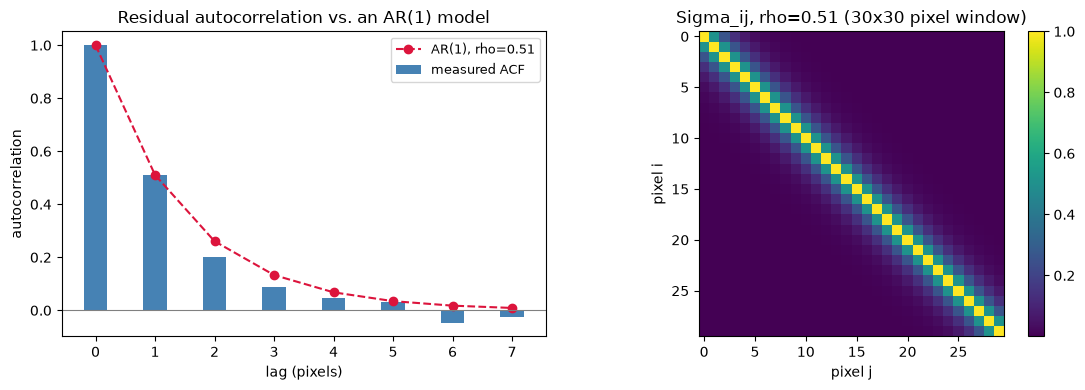


For comparison, rho=0 (independent pixels) would be a purely diagonal matrix --
off-diagonal fraction of total matrix mass at rho=0: 0.000  vs.  measured: 0.660


In [3]:
def lag_k_acf(x, k):
    x = x - np.mean(x)
    var = np.sum(x ** 2)
    if var <= 0 or k >= len(x):
        return 0.0
    return float(np.sum(x[:-k] * x[k:]) / var) if k > 0 else 1.0

measured_rho = estimate_correlation_length(residual_rho0)
lags = np.arange(0, 8)
acf = [lag_k_acf(residual_rho0, k) for k in lags]
geometric = measured_rho ** lags

print(f"measured rho (lag-1 ACF) = {measured_rho:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(lags, acf, width=0.4, color="steelblue", label="measured ACF")
ax.plot(lags, geometric, "o--", color="crimson", label=f"AR(1), rho={measured_rho:.2f}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("lag (pixels)"); ax.set_ylabel("autocorrelation")
ax.set_title("Residual autocorrelation vs. an AR(1) model")
ax.legend(fontsize=9)

ax = axes[1]
n_show = 30  # a small window -- the band structure is the point, not the full matrix
Sigma_rho0 = build_ar1_covariance(np.full(n_show, 1.0), rho=0.0)
Sigma_measured = build_ar1_covariance(np.full(n_show, 1.0), rho=measured_rho)
im = ax.imshow(Sigma_measured, cmap="viridis", origin="upper")
ax.set_title(f"Sigma_ij, rho={measured_rho:.2f} ({n_show}x{n_show} pixel window)")
ax.set_xlabel("pixel j"); ax.set_ylabel("pixel i")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

print(f"\nFor comparison, rho=0 (independent pixels) would be a purely diagonal matrix --")
print(f"off-diagonal fraction of total matrix mass at rho=0: "
      f"{1.0 - np.trace(Sigma_rho0)/Sigma_rho0.sum():.3f}  vs.  "
      f"measured: {1.0 - np.trace(Sigma_measured)/Sigma_measured.sum():.3f}")

### Cross-check: does high correlation also show up in a single, cleanly-fit spaxel?

The measurement above uses a *combined* multi-spaxel aperture, which leaves
open whether its `rho` is a property of each spaxel's own pixel noise or
partly a product of combining spaxels. **Optional** (needs the full
NGC 4751 NFM cube downloaded locally, unlike everything above -- skips cleanly
if it isn't present): repeat the same measurement on the single brightest
spaxel in the cube -- no aperture-summing at all, the cleanest possible
case for isolating whether correlation is a per-pixel property or an
artifact of combining spaxels.

In [4]:
CUBE_PATH = "muse_download/ADP.2022-12-13T15:54:49.001.fits"  # NGC 4751 MUSE NFM

if not os.path.exists(CUBE_PATH):
    print(f"cube not found at {CUBE_PATH} -- skipping the cross-check "
          "(see 04_template_calibration.ipynb to download it)")
else:
    from kinextract import load_muse_cube, extract_aperture_spectrum

    cube = load_muse_cube(CUBE_PATH)
    ny, nx = cube.shape
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        signal_map = np.nanmedian(cube.flux, axis=0)
        noise_map = np.nanmedian(cube.error, axis=0)
    good = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)
    _mc = np.atleast_2d(np.loadtxt("../data/muse/ngc4751_nfm_kma_mask.txt", skiprows=1, dtype=int))  # KMA dust cut
    _in = (_mc[:, 0] >= 0) & (_mc[:, 0] < nx) & (_mc[:, 1] >= 0) & (_mc[:, 1] < ny)
    good[_mc[_in, 1], _mc[_in, 0]] = False
    by, bx = np.unravel_index(np.nanargmax(np.where(good, signal_map, np.nan)), signal_map.shape)

    # the single brightest spaxel -- no aperture-summing at all, the cleanest
    # possible test of whether high rho survives without it.
    spaxel_mask = np.zeros((ny, nx), dtype=bool)
    spaxel_mask[by, bx] = True
    print(f"cross-check: single brightest spaxel at (y={by}, x={bx})")

    wave_obs_x, flux_obs_x, error_obs_x = extract_aperture_spectrum(cube, spaxel_mask)
    wave_rest_x = wave_obs_x / (1.0 + Z)
    in_window_x = (wave_rest_x >= WAVEFITMIN) & (wave_rest_x <= WAVEFITMAX)
    wave_wx, flux_wx, error_wx = wave_rest_x[in_window_x], flux_obs_x[in_window_x], error_obs_x[in_window_x]
    wave_fit_x, flux_fit_x = mask_wavelength_windows(wave_wx, flux_wx, windows=SKY_RESIDUAL_WINDOWS)
    _, errors_x = mask_wavelength_windows(wave_wx, error_wx, windows=SKY_RESIDUAL_WINDOWS)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        cfg_wide_x = FitConfig(vmin=-3000.0, vmax=3000.0)
    v_grid_wide_x = cfg_wide_x.build_velocity_grid()
    A_stack_wide_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_wide_x)
    y_w_x = flux_fit_x / errors_x
    result_wide_x = fit_losvd(A_stack_wide_x / errors_x[None, :, None], y_w_x, cfg_wide_x, wave_fit=wave_fit_x)
    mw_x = compute_losvd_moments(v_grid_wide_x, result_wide_x["b"], fit_h3h4=False)

    cfg_x = FitConfig(vmin=mw_x["vherm"] - NSIG * mw_x["sherm"], vmax=mw_x["vherm"] + NSIG * mw_x["sherm"])
    v_grid_x = cfg_x.build_velocity_grid()
    A_stack_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_x)
    A_stack_w_x = A_stack_x / errors_x[None, :, None]
    result_x = fit_losvd(A_stack_w_x, y_w_x, cfg_x, wave_fit=wave_fit_x)
    residual_x = y_w_x - full_pixel_model(result_x, A_stack_w_x, wave_fit_x, cfg_x)
    chi2_red_x = float(np.sum(residual_x ** 2)) / len(wave_fit_x)
    rho_x = estimate_correlation_length(residual_x)

    print(f"chi2_red={chi2_red_x:.2f}, measured rho={rho_x:.3f}")
    print("Compare with the aperture's rho in Section 3: a much lower value here means the aperture's "
          "correlation comes mostly from combining spaxels (and from residuals that grow with S/N), "
          "not from each spaxel's own pixel noise.")


  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


cross-check: single brightest spaxel at (y=169, x=180)


chi2_red=0.51, measured rho=0.089
Compare with the aperture's rho in Section 3: a much lower value here means the aperture's correlation comes mostly from combining spaxels (and from residuals that grow with S/N), not from each spaxel's own pixel noise.


## 4. The Bacon et al. 2017 connection -- and an honest discrepancy

MUSE's pipeline resamples/drizzles the original (rotated, slightly
irregular) spaxel grid onto the regular output grid every reduced cube
ships with. Bacon et al. (2017, the MUSE-DEEP survey paper) show this
resampling step smooths adjacent output pixels together, and as a direct
consequence the pipeline's own propagated per-pixel variance
**underestimates the true noise by a factor of about `(1/0.6)^2 ~
2.78`** in variance (~1.67x in sigma) -- because that propagated
variance still assumes independent input pixels, which the resampling
has just made untrue. This is a *literature-known, external* factor --
not derived here.

**What the measured `rho` depends on.** A separate measurement on real MUSE calibration-star spectra gives
`rho ~ 0.3-0.5` (continuum-detrended, averaged across several stars). The aperture above, with the continuum
co-fitted (the package default), gives about 0.5 -- the top of that range -- and the single spaxel about 0.1. Two
things set the number:
- **An unmodeled continuum.** Fitting this same aperture *without* the co-fitted continuum leaves a smooth,
  wavelength-scale mismatch in the residual: chi2_red rises from about 2.3 to 23 and the lag-1 `rho` to about 0.94.
  That is not pixel noise at all, so measure `rho` on the residual of a fit with the continuum.
- **Combining spaxels.** A combined aperture correlates more than a single spaxel. Re-measure `rho` for your own
  bins rather than assuming one value -- `fit_losvd_robust(..., measure_rho=True)` does this per bin.

In [5]:
BACON_2017_VARIANCE_FACTOR = BACON2017_VARIANCE_CORRECTION_FACTOR

errors_bacon_scaled = errors * np.sqrt(BACON_2017_VARIANCE_FACTOR)
y_w_bacon = flux_fit / errors_bacon_scaled
A_stack_w_bacon = A_stack / errors_bacon_scaled[None, :, None]
result_bacon = fit_losvd(A_stack_w_bacon, y_w_bacon, cfg, wave_fit=wave_fit)
model_w_bacon = full_pixel_model(result_bacon, A_stack_w_bacon, wave_fit, cfg)
chi2_red_bacon = float(np.sum((y_w_bacon - model_w_bacon) ** 2)) / len(wave_fit)

print(f"chi2_red, propagated errors as-is:                  {chi2_red_rho0:.2f}")
print(f"chi2_red, errors scaled by Bacon et al. 2017 factor: {chi2_red_bacon:.2f}")
print(f"(scaling the errors changes chi2_red's level, not the residual's correlation between neighboring pixels -- "
      f"whitening against the measured rho, next, accounts for that)")


chi2_red, propagated errors as-is:                  2.36
chi2_red, errors scaled by Bacon et al. 2017 factor: 0.85
(scaling the errors changes chi2_red's level, not the residual's correlation between neighboring pixels -- whitening against the measured rho, next, accounts for that)


## 5. Refit with proper GLS whitening against the measured `rho`

**What whitening actually does, conceptually.** At `rho=0` (independent
pixels), "whitening" just means dividing by each pixel's own error bar --
after that, every pixel's noise has the same (unit) scale, so a plain sum
of squares is the correct chi-squared. With `rho != 0`, no single per-pixel
number can do that job, because the noise in adjacent pixels moves
*together* -- dividing each pixel by its own error leaves that shared,
correlated part untouched. The fix is a full linear transform: factor the
covariance matrix as `Sigma = L @ L.T` (a Cholesky factorization -- always
possible for a valid covariance) and multiply the data (and the model
design matrix, identically) by `L^-1`. This mixes information *across*
pixels in exactly the way needed to cancel the shared, correlated
component, leaving residuals that really are independent and unit-scale --
so a plain sum of squares is correct again, on the *transformed* data.

`measure_and_whiten` does both steps in one call (measure `rho` from
these residuals, then whiten against it) -- the convenience wrapper for
exactly this pattern. `whiten` alone reproduces the simple
`A_stack/errors` division bit-for-bit at `rho=0`, since `L` is just
`diag(errors)` in that case. `fit_losvd` itself needs no changes at all;
it only ever consumes whatever whitened inputs it's handed (see
`FitConfig.rho`'s own docstring and `noise_model.py`'s module docstring
for why this is a deliberate design choice, not a shortcut).

In [6]:
A_stack_w_rho, y_w_rho, L, rho_used = measure_and_whiten(A_stack, flux_fit, errors, residuals=residual_rho0)
cfg_rho = FitConfig(vmin=cfg.vmin, vmax=cfg.vmax, rho=rho_used)

result_rho = fit_losvd(A_stack_w_rho, y_w_rho, cfg_rho, wave_fit=wave_fit)
moments_rho = compute_losvd_moments(v_grid, result_rho["b"], fit_h3h4=True)
model_w_rho = full_pixel_model(result_rho, A_stack_w_rho, wave_fit, cfg_rho)
chi2_red_rho = float(np.sum((y_w_rho - model_w_rho) ** 2)) / len(wave_fit)

print(f"                    rho=0 (assumed)   rho={rho_used:.2f} (measured)")
print(f"V                   {moments['vherm']:+8.1f}          {moments_rho['vherm']:+8.1f}")
print(f"sigma               {moments['sherm']:8.1f}          {moments_rho['sherm']:8.1f}")
print(f"h3                  {moments['h3']:+8.4f}          {moments_rho['h3']:+8.4f}")
print(f"h4                  {moments['h4']:+8.4f}          {moments_rho['h4']:+8.4f}")
print(f"chi2_red            {chi2_red_rho0:8.2f}          {chi2_red_rho:8.2f}")


                    rho=0 (assumed)   rho=0.51 (measured)
V                      +63.1             +62.8
sigma                  510.0             508.8
h3                   +0.0199           +0.0185
h4                   -0.0125           -0.0117
chi2_red                2.36              2.33


## 6. The consequence for reported uncertainty

Correlated noise treated as independent doesn't just get chi2_red wrong -- it also makes the uncertainty band too
narrow. The Laplace uncertainty itself needs no changes for this (see `FitConfig.rho`'s own docstring): once
`A_stack_w`/`y_w` are whitened correctly, the residual is i.i.d. by construction regardless of `rho`. The only
thing that changes is *which* whitened inputs go in.

In [7]:
lap_rho0 = laplace_losvd_uncertainty(A_stack_w, y_w, cfg, wave_fit=wave_fit, lam=result["lam_used"], seed=0)
lap_rho = laplace_losvd_uncertainty(A_stack_w_rho, y_w_rho, cfg_rho, wave_fit=wave_fit, lam=result_rho["lam_used"],
                                    seed=0)

print(f"sigma uncertainty, rho=0 (assumed):     +/-{lap_rho0['sherm_std']:.2f} km/s")
print(f"sigma uncertainty, rho={rho_used:.2f} (measured):  +/-{lap_rho['sherm_std']:.2f} km/s")
print(f"ratio: {lap_rho['sherm_std'] / lap_rho0['sherm_std']:.2f}x wider once correlation is properly accounted for")

sigma uncertainty, rho=0 (assumed):     +/-3.93 km/s
sigma uncertainty, rho=0.51 (measured):  +/-6.47 km/s
ratio: 1.65x wider once correlation is properly accounted for


## 7. Confirming the mechanism on a synthetic mock with known truth

Sections 1-6 measure a real effect on real data, but real data has no
ground truth to check recovery against directly. This section builds a
synthetic mock the same way `01_basic_mock_fit.ipynb` does, but injects
*genuinely correlated* noise via `build_ar1_covariance` (a real
Cholesky-factored draw, `L @ standard_normal`, not independent noise
dressed up) at a known `rho`, then fits it two ways: assuming
independence (`rho=0`, wrong) and whitened against the true `rho`
(correct). Because the truth is known here, this directly shows what
Section 6 could only show indirectly: the `rho=0` band isn't just
narrower, it's narrower than it should be *relative to where the truth
actually is*.

In [8]:
MOCK_TRUE_V, MOCK_TRUE_SIGMA, MOCK_SNR, MOCK_TRUE_RHO = 20.0, 90.0, 60.0, 0.7

mock_templates, mock_template_wave, *_ = load_emiles_templates(EMILES_GRID, select=[(5.0, 0.06)])
cfg_mock = FitConfig(vmin=MOCK_TRUE_V - 7 * MOCK_TRUE_SIGMA, vmax=MOCK_TRUE_V + 7 * MOCK_TRUE_SIGMA)
v_grid_mock = cfg_mock.build_velocity_grid()
b_truth_mock, _ = build_spline_truth(v_grid_mock, vel=MOCK_TRUE_V, sigma=MOCK_TRUE_SIGMA, wiggle_scale=0.0, seed=9)
A_stack_mock = build_template_stack(wave_fit, mock_template_wave, mock_templates, v_grid_mock)
galaxy_noiseless_mock = A_stack_mock[0] @ b_truth_mock
noise_level_mock = np.median(galaxy_noiseless_mock) / MOCK_SNR
errors_mock = np.full(len(wave_fit), noise_level_mock)

# A REAL correlated draw -- L @ standard_normal has covariance Sigma by construction,
# not independent noise dressed up to look correlated after the fact.
Sigma_true = build_ar1_covariance(errors_mock, MOCK_TRUE_RHO)
L_true = np.linalg.cholesky(Sigma_true)
rng_mock = np.random.default_rng(3)
galaxy_mock = galaxy_noiseless_mock + L_true @ rng_mock.standard_normal(len(wave_fit))

# Fit assuming independence (wrong) and whitened against the TRUE rho (correct) --
# using the injected truth directly here, not a re-measured estimate, to isolate the
# whitening mechanism itself from any separate rho-estimation error.
A_w0_mock, y_w0_mock, _ = whiten(A_stack_mock, galaxy_mock, errors_mock, rho=0.0)
lap0_mock = laplace_losvd_uncertainty(A_w0_mock, y_w0_mock, cfg_mock, wave_fit=wave_fit, seed=0)

A_wr_mock, y_wr_mock, _ = whiten(A_stack_mock, galaxy_mock, errors_mock, rho=MOCK_TRUE_RHO)
cfg_r_mock = FitConfig(vmin=cfg_mock.vmin, vmax=cfg_mock.vmax, rho=MOCK_TRUE_RHO)
lapr_mock = laplace_losvd_uncertainty(A_wr_mock, y_wr_mock, cfg_r_mock, wave_fit=wave_fit, seed=0)

print(f"true sigma = {MOCK_TRUE_SIGMA:.1f} km/s, true rho = {MOCK_TRUE_RHO:.2f}")
print(f"rho=0 (wrong)     : sigma = {lap0_mock['point0']['sherm']:.1f} +/- {lap0_mock['sherm_std']:.2f} km/s")
print(f"rho=0.7 (correct) : sigma = {lapr_mock['point0']['sherm']:.1f} +/- {lapr_mock['sherm_std']:.2f} km/s")
print(f"ratio: {lapr_mock['sherm_std'] / lap0_mock['sherm_std']:.2f}x wider once the true correlation is "
      f"properly accounted for")
print()
print("The point estimate barely moves (whitening changes the WEIGHT each pixel carries, not the data); the")
print("reported uncertainty is what changes. How much depends on the spectrum as well as on rho: 1.1x here,")
print("against 1.65x for the real aperture of Section 6.")


true sigma = 90.0 km/s, true rho = 0.70
rho=0 (wrong)     : sigma = 84.4 +/- 3.10 km/s
rho=0.7 (correct) : sigma = 85.0 +/- 3.45 km/s
ratio: 1.11x wider once the true correlation is properly accounted for

The point estimate barely moves (whitening changes the WEIGHT each pixel carries, not the data); the
reported uncertainty is what changes. How much depends on the spectrum as well as on rho: 1.1x here,
against 1.65x for the real aperture of Section 6.


## 8. Systematic residuals: sky lines and template mismatch

Correlated noise is only one way a real spectrum departs from the error array. At high S/N the larger effect is
**systematic residuals**, which no `rho` describes:
- **Sky-line residuals:** the pipeline's sky subtraction leaves narrow spikes, 10-60 % of the continuum, at the
  positions of the OH lines.
- **Template mismatch:** no template mixture reproduces the galaxy exactly. The misfit grows in proportion to the
  model.

On NGC 4751, the reduced chi2 before any error inflation grows with S/N, from about 2 at S/N 25 to more than 40 at
S/N 250. That is the signature of residuals that do not shrink with the photon noise.

`noise_model_errors` fits a per-pixel variance to the residuals of a preliminary fit:

  `sigma_pix^2 = err^2 + (kappa * s)^2 + (f * model)^2`

Here `s` is the LSF-blended sky-line spectrum (`sky_line_profile`, from the MUSE pipeline's line catalog), and
`kappa` and `f` are fitted by maximum likelihood. On a spectrum without these systematics both terms go to about
zero and the errors are unchanged.

**Use these errors for the uncertainty bands, not for the fit.** At a fixed `lam`, near-uniformly larger errors act
as a stronger penalty and over-smooth the LOSVD. On 480 NGC 4751-like mocks, fitting with them made the shapes
18-32 % worse at high S/N. So the recipe is:
1. Fit with the plain errors.
2. Run Laplace with the noise-model errors at the same `lam`.
3. Move the draws onto the plain fit with `recenter_samples`.

`losvd_error_bands` does steps 2-3 in one call (Section 8.1). `dev_notes/regularization_v2/FINDINGS.md` has the
validation.

sky term kappa = 0.005 x median model;  mismatch term f = 0.17 %;  median error inflation = 1.38x


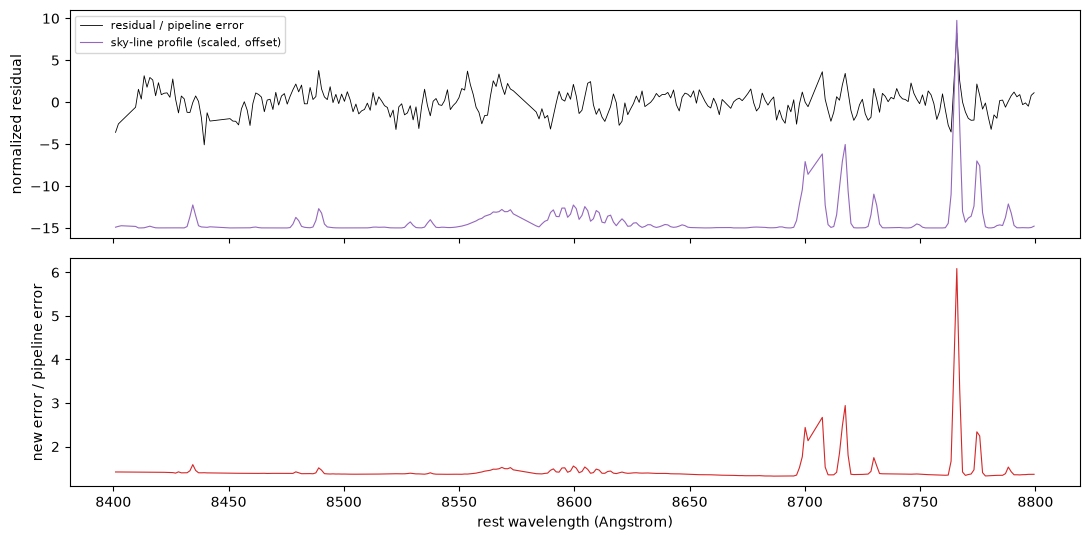

In [9]:
import urllib.request
from kinextract import (load_muse_sky_lines, sky_line_profile, noise_model_errors, fit_losvd_robust,
                        losvd_error_bands)

# The MUSE pipeline's sky-line catalog (ESO static calibration MU_GSKL_140101A, 1 MB), fetched once.
SKY_LINES_PATH = "muse_download/MU_GSKL_140101A_sky_lines.fits"
SKY_LINES_URL = "https://dataportal.eso.org/dataportal_new/file/M.MUSE.2023-07-03T08:28:46.633"
if not os.path.exists(SKY_LINES_PATH):
    os.makedirs(os.path.dirname(SKY_LINES_PATH), exist_ok=True)
    urllib.request.urlretrieve(SKY_LINES_URL, SKY_LINES_PATH)
line_wave, line_flux = load_muse_sky_lines(SKY_LINES_PATH)
sky = sky_line_profile(wave_fit, line_wave, line_flux, z=Z)        # rest-frame grid; observed-frame line list

nm = noise_model_errors(A_stack, flux_fit, errors, wave_fit, cfg, sky)
print(f"sky term kappa = {nm['kappa']:.3f} x median model;  mismatch term f = {100 * nm['f']:.2f} %;  "
      f"median error inflation = {nm['inflation']:.2f}x")

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax[0].plot(wave_fit, (flux_fit - nm["model"]) / errors, "k", lw=0.6, label="residual / pipeline error")
ax[0].plot(wave_fit, 10 * sky - 15, color="tab:purple", lw=0.8, label="sky-line profile (scaled, offset)")
ax[0].set_ylabel("normalized residual"); ax[0].legend(fontsize=8)
ax[1].plot(wave_fit, nm["errors"] / errors, color="tab:red", lw=0.8)
ax[1].set_ylabel("new error / pipeline error"); ax[1].set_xlabel("rest wavelength (Angstrom)")
plt.tight_layout(); plt.show()

### 8.1 Error bands for real data: `losvd_error_bands`

The recipe, in one call per bin after the fit (`fit_losvd_robust`, with the plain errors):
1. the noise model above, measured on a preliminary fit;
2. the Laplace posterior with those errors (times the robust fit's own inflation), at the fit's `lam` and `rho`,
   without its clipped pixels;
3. the draws moved onto the fit with `recenter_samples`, a per-velocity shift in log b followed by
   renormalization to unit area -- the point estimate keeps the plain-error fit's better shape, and the band
   widens where the systematics say it should;
4. the moment errors, as half the 16-84 % range of the draws' moments.

On this spectrum the band comes out several times wider than the pipeline errors alone would give.
`losvd_error_bands_parallel` runs it over many bins (`07_full_galaxy_analysis.ipynb`).

lam 45813;  V +75.1 +/- 12.3  sigma 527.4 +/- 6.4  h3 +0.027 +/- 0.008  h4 -0.008 +/- 0.006


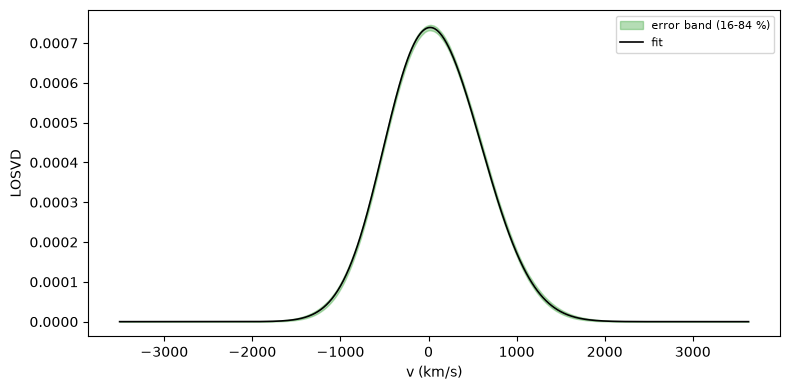

In [10]:
fit = fit_losvd_robust(A_stack, flux_fit, errors, cfg, wave_fit=wave_fit)
bands = losvd_error_bands(A_stack, flux_fit, errors, wave_fit, fit, cfg, sky_profile=sky)
m_fit = compute_losvd_moments(v_grid, fit["b"], fit_h3h4=True)

print(f"lam {fit['lam_used']:.0f};  V {m_fit['vherm']:+.1f} +/- {bands['vherm_err']:.1f}  "
      f"sigma {m_fit['sherm']:.1f} +/- {bands['sherm_err']:.1f}  "
      f"h3 {m_fit['h3']:+.3f} +/- {bands['h3_err']:.3f}  h4 {m_fit['h4']:+.3f} +/- {bands['h4_err']:.3f}")

b0 = fit["b"] / np.trapezoid(fit["b"], v_grid)
plt.figure(figsize=(8, 4))
plt.fill_between(v_grid, bands["b_p16"], bands["b_p84"], color="tab:green", alpha=0.35, label="error band (16-84 %)")
plt.plot(v_grid, b0, "k", lw=1.2, label="fit")
plt.xlabel("v (km/s)"); plt.ylabel("LOSVD"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Conclusion

**What this notebook did.** Measured whether real MUSE pixel noise is
actually independent (it isn't), quantified the correlation with a
single AR(1) parameter `rho`, and traced its consequences: a
systematically elevated `chi2_red` under the independence assumption, a
too-narrow uncertainty band, and confirmation of the whole mechanism on a
synthetic mock with known, injected correlation. Then added the
systematic residuals of real spectra and the error bands that carry them.

**Key takeaways:**

- A combined, high-S/N NGC 4751 aperture shows moderate pixel-to-pixel
  correlation (`rho ~ 0.5`) once the continuum is co-fitted; a single
  spaxel shows much less (~0.1). Without the continuum the residual's
  `rho` rises to ~0.94 -- an unmodeled continuum, not pixel noise.
- Treating correlated noise as independent doesn't just bias `chi2_red`;
  it makes the uncertainty band too narrow, understating how
  uncertain the recovered kinematics really are.
- GLS whitening (factor the covariance, transform both data and design
  matrix) fixes this at the source -- `fit_losvd` and the Laplace
  uncertainty need no changes at all, since they only ever consume
  whatever whitened inputs they're handed.
- The synthetic mock (Section 7) confirms the mechanism directly against
  known truth: the point estimate barely moves, but the reported
  uncertainty does -- whitening changes how much *weight* each pixel
  carries, not the data itself.
- **`rho` is not a universal number.** It depends on how spaxels are
  combined and on whether the fit models the continuum -- re-measure it
  per bin (`fit_losvd_robust(..., measure_rho=True)`) rather than assuming
  one value.
- `FitConfig.rho` is a carrier field, not automatically applied -- every
  whitening step in this notebook called `whiten`/`measure_and_whiten`
  explicitly.
- **Systematic residuals (Section 8)** are a different problem from
  correlated noise. Sky-line residuals and template mismatch add variance
  that grows with S/N. `noise_model_errors` measures it, and
  `losvd_error_bands` uses it for the error bands only, re-centered on
  the plain-error fit.

**Next**: `07_full_galaxy_analysis.ipynb` carries this same measured
`rho` into a real, full-galaxy analysis at scale, alongside the
calibrated template subset from `04_template_calibration.ipynb`.

See `kinextract.noise_model`'s module docstring for the AR(1) covariance
design and `kinextract.laplace_uncertainty`'s for the error bands.